# Designing Tools for Agents: Fix a Refund Agent Without Touching Its Prompt

**A support agent works through 10 refund tickets in a fake store whose right answers are planted in advance. The model, the prompt and the loop stay fixed. Only the tools change. A thin wrapper generated from the store's internal API resolves 18 of 30 runs, and on two of the tickets it refunds the customer twice every time. Four tools designed for the model resolve all 30. This notebook shows why, one trace at a time, and reports what better descriptions alone could and could not fix.**

## The one idea

The model never reads your code. It meets a tool through text alone: a name, a description and a parameter list before the call, and a result or an error after it. To the model, that text is the tool. A wrapper generated from an internal API is written for the code that calls it: terse summaries, opaque IDs, amounts in cents, dates as unix timestamps, every field of every record, and bare HTTP errors. Designing tools for the model, what the SWE-agent paper calls the **agent-computer interface** ([Yang et al., 2024](https://arxiv.org/abs/2405.15793)), means a few tools shaped around the task, readable values, results cut to what the next decision needs, errors that say what to do next, and writes that are safe to repeat ([Anthropic, 2025](https://www.anthropic.com/engineering/writing-tools-for-agents)).

## Overview

1. Build a store with 104 orders and 10 tickets with planted answers, plus two planted faults: a payment service that answers after the tool has given up, and a search index that times out
2. Put the same internal API behind every tool set, so only the layer the model sees differs
3. Write the bare agent loop and a scorer that checks the store's final state
4. Tool set A: one tool per endpoint, generated from the API spec. Run it and read the traces
5. Tool set B: the same endpoints and results, with the descriptions rewritten for a model
6. Tool set C: four tools designed for the model
7. Tool set D: C plus tool-use examples
8. Compare success, double refunds, failed searches, steps, tokens and dollars, then read every failure

**Requirements:** `pip install openai tiktoken matplotlib` and an `OPENAI_API_KEY`. Each tool set runs the 10 tickets 3 times: 120 agent runs, about 450 calls to `gpt-5.4-mini`, about $0.40 together at the list prices of 2026-10-30, and a minute or two of wall time, because tickets run in parallel threads. Outputs saved in this notebook come from a real run. Yours will differ, because the model is not deterministic.

> 📖 This notebook is the hands-on side of Chapter 5, "Designing Tools the Model Can Use", of [*AI Agents Made Simple*](https://europe-west1-rag-techniques-views-tracker.cloudfunctions.net/rag-techniques-tracker?notebook=all-agents-tutorials--designing-tools-for-agents&click=book-nb-agents-top&target=https%3A%2F%2Fwww.amazon.com%2Fdp%2FB0HNXRSRH2%3Fmaas%3Dmaas_adg_api_580351185840460851_static_9_573%26ref_%3Daa_maas%26tag%3Dmaas%26aa_campaignid%3Dagents-en%26aa_adgroupid%3Dgithub-notebook%26aa_creativeid%3Dgenai-designing-tools-top&retarget=0&text=book-nb-agents-top), by the author of this repository.

In [1]:
# !pip install openai tiktoken matplotlib
import json, random, string, time, copy
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from datetime import date, datetime, timedelta, timezone
import openai, tiktoken
import numpy as np
import matplotlib.pyplot as plt

MODEL = "gpt-5.4-mini"
# USD per 1M tokens, from https://developers.openai.com/api/docs/pricing on 2026-10-30. Check yours.
PRICE = {"input": 0.75, "cached_input": 0.075, "output": 4.50}
client = openai.OpenAI()          # reads OPENAI_API_KEY from the environment
enc = tiktoken.get_encoding("o200k_base")   # only used to size definitions and results; totals come from the API

## 1. A job with a known answer

The store has five customers and 104 orders. Each ticket comes from a signed-in customer and asks for a refund or a cancellation. The generator plants the right outcome of every ticket (which orders get refunded, by how much, and which get cancelled) so the score is exact: when the agent stops, compare what the store recorded with the plan. Nothing is graded by an LLM.

Each ticket carries one trap that support agents hit in production:

- **T01, T02, charged twice.** Refund one of the two identical charges. On T01 the payment service makes the refund but answers after the tool has given up.
- **T03, T04, a broken item.** Refund that item only. T04's customer bought two mug sets and one broke, so the refund is one unit. T03's refund also times out.
- **T05, a returned order.** Refund all of it.
- **T06, T07, not shipped yet.** Cancel, don't refund: nothing has been charged.
- **T08, T09, no order number.** Find the order from an item and a date among the customer's 35 orders. T08 has a decoy lamp order in May, and its refund times out. On T09 the first search hits an index timeout.
- **T10, someone else's order.** The order number belongs to a different customer, so the right outcome is no refund at all.

In [2]:
PRODUCTS = {"Wireless mouse": 2499, "Desk lamp": 4900, "Yoga mat": 3200, "USB-C charger": 3999, "Noise-cancelling headphones": 18900,
            "Backpack": 6900, "Phone case": 1999, "Mechanical keyboard": 11900, "Coffee grinder": 5400, "French press": 2900,
            "Running socks, 3-pack": 1500, "Bluetooth speaker": 7900, "Notebook, 2-pack": 1200, "HDMI cable": 1100,
            "Monitor stand": 4500, "Webcam": 5900, "Laptop sleeve": 2700, "Desk mat": 2200, "Water bottle": 1800, "Ceramic mug set": 3400}
PEOPLE = [("Dana Levi", 35), ("Omar Haddad", 12), ("Mia Chen", 35), ("Lucas Brandt", 10), ("Priya Nair", 12)]   # orders on file

def rid(rng, prefix, n):          # the opaque IDs internal systems use
    return prefix + "".join(rng.choice(string.ascii_letters + string.digits) for _ in range(n))

def stamp(d, rng):                # internal APIs store dates as unix timestamps
    return int(datetime(d.year, d.month, d.day, 9, tzinfo=timezone.utc).timestamp()) + rng.randint(0, 40000)

def day(t):
    return datetime.fromtimestamp(t, timezone.utc).date().isoformat()

def payment(rng, amount, t):
    return {"id": rid(rng, "pi_", 24), "object": "payment", "amount": amount, "amount_captured": amount, "amount_refunded": 0,
            "status": "succeeded", "created": t + rng.randint(5, 90), "method": {"type": "card", "brand": "visa", "last4": "4242"},
            "processor_ref": rid(rng, "ch_", 24), "metadata": {}}

def raw_order(rng, n, cid, email, placed, lines):     # lines: (sku, qty, unit price in cents)
    t, total = stamp(placed, rng), sum(q * p for _, q, p in lines)
    return {"id": n, "object": "order", "customer": cid, "email": email, "created": t, "updated": t + rng.randint(90000, 900000),
            "currency": "usd", "status": "fulfilled", "fulfillment_status": "delivered", "financial_status": "paid",
            "line_items": [{"id": rid(rng, "li_", 12), "sku": s, "quantity": q, "unit_amount": p, "tax_amount": 0, "discount_amount": 0,
                            "fulfillment_id": rid(rng, "ful_", 10), "warehouse": rng.choice(["WH-NJ-02", "WH-TX-01", "WH-NV-03"]),
                            "metadata": {}} for s, q, p in lines],
            "amount_total": total, "payments": [payment(rng, total, t)], "refunds": [],
            "shipping": {"carrier": rng.choice(["UPS", "FedEx", "USPS"]), "tracking": rid(rng, "1Z", 16), "service": "ground",
                         "address_id": rid(rng, "addr_", 10)},
            "tags": [], "notes": None, "source": rng.choice(["web", "ios", "android"]), "channel_id": rid(rng, "chn_", 8),
            "risk": {"score": rng.randint(2, 40), "level": "normal"}, "cancelled_at": None, "cancel_reason": None,
            "audit": {"created_by": "svc-checkout", "last_modified_by": "svc-fulfillment", "version": rng.randint(3, 9)}}

def make_world(seed=11):
    rng = random.Random(seed)
    skus = {}
    for name, price in PRODUCTS.items():
        s = f"SKU-{rng.randint(10000, 99999)}"
        skus[s] = {"sku": s, "object": "sku", "name": name, "price": price, "currency": "usd", "active": True,
                   "inventory_id": rid(rng, "inv_", 10), "metadata": {}}
    sku_of = {v["name"]: k for k, v in skus.items()}
    customers, orders, cid_of = {}, {}, {}
    numbers = rng.sample(range(6100, 6500), sum(size for _, size in PEOPLE))
    for name, size in PEOPLE:
        cid, email = rid(rng, "cus_", 14), name.lower().replace(" ", ".") + "@example.com"
        customers[cid] = {"id": cid, "object": "customer", "email": email, "name": name, "created": stamp(date(2024, 5, 1), rng),
                          "default_payment_method": rid(rng, "pm_", 24), "tier": "standard", "metadata": {}}
        cid_of[name] = cid
        for _ in range(size):
            placed = date(2026, 3, 1) + timedelta(days=rng.randint(0, 220))
            items = rng.sample(sorted(PRODUCTS), rng.choice([1, 1, 2, 2, 3]))
            lines = [(sku_of[i], rng.choice([1, 1, 1, 2]), PRODUCTS[i]) for i in items]
            orders[numbers.pop()] = raw_order(rng, None, cid, email, placed, lines)
    for n, o in orders.items():
        o["id"] = n
    return rng, skus, sku_of, customers, orders, cid_of

In [3]:
def plant(seed=11):
    rng, skus, sku_of, customers, orders, cid_of = make_world(seed)
    email = {cid: c["email"] for cid, c in customers.items()}
    tickets, used = [], set()

    def own(name):                         # an unused order of this customer, chosen at random
        n = rng.choice(sorted(n for n, o in orders.items() if o["customer"] == cid_of[name] and n not in used))
        used.add(n)
        return n

    def rebuild(n, name, placed, lines):   # replace an order's contents with planted ones
        o = raw_order(rng, n, cid_of[name], email[cid_of[name]], placed, [(sku_of[i], q, PRODUCTS[i]) for i, q in lines])
        orders[n] = o
        return o

    lamp = sku_of["Desk lamp"]             # ticket T08 needs exactly two desk lamp orders on Dana's account
    for n, o in list(orders.items()):
        if o["customer"] == cid_of["Dana Levi"] and any(li["sku"] == lamp for li in o["line_items"]):
            rebuild(n, "Dana Levi", date.fromisoformat(day(o["created"])), [("Water bottle", 1)])

    def duplicate(o):                      # the processor captured the same payment twice
        o["payments"].append(payment(rng, o["amount_total"], o["created"]))

    def unshipped(o):                      # authorized, not captured: nothing has been charged yet
        o.update(status="open", fulfillment_status="unfulfilled", financial_status="authorized")
        o["payments"][0].update(status="requires_capture", amount_captured=0)
        o["shipping"]["tracking"] = None

    def add(tid, kind, name, text, refunds=None, cancels=(), faults=(), number_given=True):
        tickets.append({"id": tid, "kind": kind, "customer": cid_of[name], "email": email[cid_of[name]], "text": text, "faults": set(faults),
                        "expect_refunds": refunds or {}, "expect_cancels": set(cancels), "number_given": number_given})

    # 1-2. Charged twice, order number given. On T01 the first refund the processor accepts answers after the tool's timeout.
    for tid, name, text in [("T01", "Dana Levi", "I was charged twice for order {n}. Please refund the duplicate charge."),
                            ("T02", "Mia Chen", "My card statement shows two identical charges for order {n}. Please fix it.")]:
        n = own(name); duplicate(orders[n])
        add(tid, "charged twice", name, text.format(n=n), refunds={n: orders[n]["amount_total"]},
            faults={"refund_timeout"} if tid == "T01" else ())
    # 3-4. One item broken, order number given. The order JSON names items only by SKU.
    n = own("Omar Haddad"); rebuild(n, "Omar Haddad", date(2026, 9, 3), [("French press", 1), ("Wireless mouse", 1), ("Desk mat", 1)])
    add("T03", "broken item", "Omar Haddad", f"The wireless mouse in order {n} arrived broken. Please refund just the mouse, I'm keeping the rest.",
        refunds={n: PRODUCTS["Wireless mouse"]}, faults={"refund_timeout"})
    n = own("Lucas Brandt"); rebuild(n, "Lucas Brandt", date(2026, 8, 21), [("Ceramic mug set", 2), ("Coffee grinder", 1)])
    add("T04", "1 of 2 broken", "Lucas Brandt", f"One of the two ceramic mug sets in order {n} arrived cracked. Please refund that one set.",
        refunds={n: PRODUCTS["Ceramic mug set"]})
    # 5. A returned order: refund it in full.
    n = own("Priya Nair"); o = orders[n]; o.update(fulfillment_status="returned", tags=["return_received"])
    add("T05", "returned", "Priya Nair", f"I sent order {n} back and got the email saying the return was received. Please refund it.",
        refunds={n: o["amount_total"]})
    # 6-7. Not shipped yet: the right move is to cancel, not refund.
    for tid, name, text in [("T06", "Dana Levi", "Please refund order {n}, I ordered it by mistake."),
                            ("T07", "Omar Haddad", "Cancel my order {n} and refund me please, I found it cheaper elsewhere.")]:
        n = own(name); unshipped(orders[n]); orders[n]["created"] = stamp(date(2026, 10, 27), rng)
        orders[n]["payments"][0]["created"] = orders[n]["created"] + 40
        add(tid, "not shipped", name, text.format(n=n), cancels={n})
    # 8. No order number: find the right desk lamp order among 35, with a decoy lamp order in May. The refund times out.
    n = own("Dana Levi"); rebuild(n, "Dana Levi", date(2026, 9, 16), [("Desk lamp", 1), ("HDMI cable", 2)])
    m = own("Dana Levi"); rebuild(m, "Dana Levi", date(2026, 5, 9), [("Desk lamp", 1)])
    add("T08", "no number", "Dana Levi", "I bought a desk lamp from you in mid-September and it stopped working after one day. "
        "Can you refund it? I don't have the order number.", refunds={n: PRODUCTS["Desk lamp"]}, faults={"refund_timeout"},
        number_given=False)
    # 9. No order number, and the first search hits an index timeout (the API still answers 200, with zero hits).
    for m, o in orders.items():
        if o["customer"] == cid_of["Mia Chen"] and day(o["created"]) == "2026-09-14" and m not in used:
            o["created"] -= 86400 * 3
    n = own("Mia Chen")
    o = rebuild(n, "Mia Chen", date(2026, 9, 14), [("Yoga mat", 1), ("Water bottle", 2)]); duplicate(o)
    add("T09", "no number, outage", "Mia Chen", "My card was charged twice for my order from September 14, the one with the yoga mat. "
        "Please refund the extra charge. Sorry, I don't have the order number.", refunds={n: o["amount_total"]},
        faults={"search_timeout"}, number_given=False)
    # 10. The order number in the ticket belongs to a different customer. The right outcome is no refund.
    n = own("Lucas Brandt"); rebuild(n, "Lucas Brandt", date(2026, 9, 25), [("Bluetooth speaker", 1)])
    add("T10", "not their order", "Priya Nair", f"The Bluetooth speaker in order {n} arrived damaged. Please refund it.")
    return tickets, skus, customers, orders

TICKETS, SKUS, CUSTOMERS, ORDERS = plant()
print(f"{len(CUSTOMERS)} customers, {len(ORDERS)} orders, {len(TICKETS)} tickets\n")
for t in TICKETS:
    want = [f"refund ${c / 100:.2f} on {n}" for n, c in t["expect_refunds"].items()] + [f"cancel {n}" for n in t["expect_cancels"]]
    print(f"{t['id']}  {t['kind']:18} {', '.join(sorted(t['faults'])) or '-':15} -> {', '.join(want) or 'no refund, no cancel'}")
print("\n" + TICKETS[7]["text"])

5 customers, 104 orders, 10 tickets

T01  charged twice      refund_timeout  -> refund $34.00 on 6450
T02  charged twice      -               -> refund $50.98 on 6269
T03  broken item        refund_timeout  -> refund $24.99 on 6263
T04  1 of 2 broken      -               -> refund $34.00 on 6216
T05  returned           -               -> refund $27.00 on 6300
T06  not shipped        -               -> cancel 6417
T07  not shipped        -               -> cancel 6425
T08  no number          refund_timeout  -> refund $49.00 on 6294
T09  no number, outage  search_timeout  -> refund $68.00 on 6414
T10  not their order    -               -> no refund, no cancel

I bought a desk lamp from you in mid-September and it stopped working after one day. Can you refund it? I don't have the order number.


## 2. The store's internal API

Every tool set in this notebook calls the same internal methods below, with the same planted faults, and every run gets a fresh copy of the store. So the only thing that changes between tool sets is the layer the model sees. Two faults are worth reading in the code:

- `refund_timeout`: the payment service makes the refund, then answers too late. The tool sees a timeout, but the money has already moved. This is how agents refund twice.
- `search_timeout`: the search index times out, and the API still answers `200 OK` with zero hits and `"timed_out": true`, the way some search engines report a partial result. A failed search that looks like an empty one.

The payment service honors an idempotency key if the caller sends one, as most payment APIs do. Only the tool sets designed for the model will send it.

In [4]:
class APIError(Exception):
    def __init__(self, status, code):
        super().__init__(f"{status} {code}"); self.status, self.code = status, code

class Timeout(Exception):
    pass

class StoreAPI:
    """The store's internal services. Every tool set calls these same methods, and every run gets a fresh copy."""
    def __init__(self, faults=()):
        self.orders, self.faults = copy.deepcopy(ORDERS), set(faults)
        self.refunds, self.cancels, self.keys = [], [], {}       # every write, recorded for scoring

    def get_order(self, n):
        if n not in self.orders: raise APIError(404, "not_found")
        return self.orders[n]

    def list_orders(self, customer=None, q=None, created_gte=None, created_lte=None, limit=100):
        if "search_timeout" in self.faults:                    # the index timed out: 200 OK, no hits
            self.faults.discard("search_timeout")
            return {"object": "list", "data": [], "has_more": False, "total_count": 0, "timed_out": True, "took_ms": 5003}
        hits = [o for o in self.orders.values()
                if (customer is None or o["customer"] == customer)
                and (q is None or q.lower() in f"{o['id']} {o['email']} {' '.join(li['sku'] for li in o['line_items'])}".lower())
                and (created_gte is None or o["created"] >= created_gte) and (created_lte is None or o["created"] <= created_lte)]
        hits.sort(key=lambda o: -o["created"])
        return {"object": "list", "data": hits[:limit], "has_more": len(hits) > limit, "total_count": len(hits), "timed_out": False, "took_ms": 41}

    def lookup_customer(self, email):
        for c in CUSTOMERS.values():
            if c["email"] == email.strip().lower(): return c
        raise APIError(404, "not_found")

    def get_sku(self, sku):
        if sku not in SKUS: raise APIError(404, "not_found")
        return SKUS[sku]

    def find_payment(self, pid):
        for o in self.orders.values():
            for p in o["payments"]:
                if p["id"] == pid: return o, p
        raise APIError(404, "not_found")

    def create_refund(self, pid, amount=None, line_item=None, reason=None, idempotency_key=None):
        if idempotency_key in self.keys: return self.keys[idempotency_key]      # the service honors keys, if you send one
        o, p = self.find_payment(pid)
        if p["status"] != "succeeded": raise APIError(409, "conflict")
        if reason not in ("duplicate", "product_defect", "return", "customer_request"): raise APIError(400, "invalid_request")
        left = p["amount_captured"] - p["amount_refunded"]
        amount = left if amount is None else amount
        if amount <= 0 or amount > left: raise APIError(400, "invalid_request")
        li = next((x for x in o["line_items"] if x["id"] == line_item), None)
        if amount < p["amount_captured"] and li is None: raise APIError(400, "invalid_request")   # partial needs a line item
        if li and amount > li["quantity"] * li["unit_amount"]: raise APIError(400, "invalid_request")
        p["amount_refunded"] += amount
        r = {"id": rid(random, "re_", 24), "object": "refund", "payment": pid, "amount": amount, "status": "succeeded",
             "line_item": line_item, "reason": reason, "created": int(time.time())}
        o["refunds"].append(r); self.refunds.append({"order": o["id"], "amount": amount})
        if idempotency_key: self.keys[idempotency_key] = r
        if "refund_timeout" in self.faults:                      # done, but the answer arrives after the tool gave up
            self.faults.discard("refund_timeout"); raise Timeout()
        return r

    def find_refund(self, idempotency_key):
        return self.keys.get(idempotency_key)

    def cancel_order(self, n):
        o = self.get_order(n)
        if o["status"] == "cancelled": return o
        if o["fulfillment_status"] != "unfulfilled": raise APIError(409, "conflict")
        o.update(status="cancelled", financial_status="voided", cancel_reason="customer_request")
        o["payments"][0]["status"] = "canceled"
        self.cancels.append(n)
        return o

## 3. The agent loop and the scorer

The loop is the bare one from the [while-loop notebook](agent_while_loop_from_scratch.ipynb): call the model, run the tools it asks for, append the results, and repeat until it answers in text. The system prompt holds the refund policy and is identical for every tool set.

One API detail: `gpt-5.4-mini` is a reasoning model, and on Chat Completions it accepts function tools only with `reasoning_effort="none"` (any other value gets a 400 error that says to use `none` or the Responses API), so every call here uses that setting.

In [5]:
SYSTEM = """You are the support agent for Northwind, an online store. Today is 2026-10-28.
Each conversation is one ticket from a signed-in customer. Resolve it with the tools, then reply to the customer in one or two sentences.

Policy:
- Charged twice for one order: refund the extra charge in full.
- An item arrived broken or stopped working: refund that item's price (one unit, if only one unit is affected).
- A returned order (return received): refund the whole order.
- An order that has not shipped: cancel it instead of refunding. Nothing has been charged yet.
- Act only on orders that belong to the signed-in customer.
- Never refund the same thing twice."""
MAX_STEPS = 15

def usd(cents):
    return f"${cents / 100:,.2f}"

def call_model(messages, tools):
    for attempt in range(5):
        try:   # gpt-5.4-mini accepts function tools on Chat Completions only with reasoning_effort="none"
            return client.chat.completions.create(model=MODEL, messages=messages, tools=tools, reasoning_effort="none")
        except (openai.RateLimitError, openai.APIConnectionError, openai.InternalServerError):
            if attempt == 4: raise
            time.sleep(5 * (attempt + 1))

def run_ticket(ticket, make_tools):
    api = StoreAPI(ticket["faults"])
    definitions, call = make_tools(api, {"customer": ticket["customer"], "ticket": ticket["id"]})
    messages = [{"role": "system", "content": SYSTEM},
                {"role": "user", "content": f"Signed-in customer: {ticket['email']}\n\n{ticket['text']}"}]
    trace, usage, reply = [], [], None
    for step in range(1, MAX_STEPS + 1):          # the bare loop: call, run the tools, append, repeat
        r = call_model(messages, definitions)
        u = r.usage
        usage.append((u.prompt_tokens, (u.prompt_tokens_details.cached_tokens or 0) if u.prompt_tokens_details else 0, u.completion_tokens))
        m = r.choices[0].message
        if not m.tool_calls:
            reply = m.content; break
        messages.append({"role": "assistant", "content": m.content, "tool_calls": [
            {"id": c.id, "type": "function", "function": {"name": c.function.name, "arguments": c.function.arguments}} for c in m.tool_calls]})
        for c in m.tool_calls:
            try: args = json.loads(c.function.arguments or "{}")
            except json.JSONDecodeError: args = {}
            out, kind = call(c.function.name, args)
            trace.append({"step": step, "tool": c.function.name, "args": args, "kind": kind, "out": out, "tokens": len(enc.encode(out))})
            messages.append({"role": "tool", "tool_call_id": c.id, "content": out})
    return {"ticket": ticket["id"], "trace": trace, "usage": usage, "reply": reply, "refunds": api.refunds, "cancels": api.cancels}

The scorer reads the store, not the agent's reply. A ticket counts as resolved only if the refunds and cancellations it caused are exactly the planted ones. On the way, it counts three kinds of mistake:

- **wrong-tool calls:** a search when the ticket gave the order number, a refund on an order that has not shipped, or a cancel on one that has
- **rejected arguments:** calls the tool refused because of their arguments
- **searches without the order:** on T08 and T09, searches that came back without the order the ticket is about

In [6]:
SEARCH_TOOLS = {"ordersList", "orders_search"}

def grade(ticket, run):
    got = defaultdict(int)
    for r in run["refunds"]: got[r["order"]] += r["amount"]
    got, cancels = dict(got), set(run["cancels"])
    if got == ticket["expect_refunds"] and cancels == ticket["expect_cancels"]: return "resolved"
    if any(ORDERS[n]["customer"] != ticket["customer"] for n in list(got) + list(cancels)): return "acted on another customer's order"
    if any(got.get(n, 0) > c for n, c in ticket["expect_refunds"].items()): return "refunded too much"
    if set(got) - set(ticket["expect_refunds"]): return "refunded the wrong order"
    if ticket["expect_cancels"] - cancels: return "did not cancel"
    if got: return "wrong refund amount"
    return "did nothing"

def measure(runs):
    by_id = {t["id"]: t for t in TICKETS}
    rows = []
    for run in runs:
        t = by_id[run["ticket"]]
        calls = run["trace"]
        wrong_tool = sum(x["kind"] == "wrong_tool" for x in calls) + sum(t["number_given"] and x["tool"] in SEARCH_TOOLS for x in calls)
        sent, cached, out = (sum(u[k] for u in run["usage"]) for k in range(3))
        rows.append({"ticket": t["id"], "outcome": grade(t, run), "steps": len(run["usage"]), "calls": len(calls),
                     "bad_args": sum(x["kind"] == "bad_args" for x in calls), "wrong_tool": wrong_tool,
                     "input": sent, "cached": cached, "output": out,
                     "cost": ((sent - cached) * PRICE["input"] + cached * PRICE["cached_input"] + out * PRICE["output"]) / 1e6,
                     "absorbed": sum("repeats an earlier call" in x["out"] for x in calls),
                     "missed_search": sum(x["tool"] in SEARCH_TOOLS and not t["number_given"] and x["kind"] == "ok"
                                          and not any(str(n) in x["out"] for n in t["expect_refunds"]) for x in calls),
                     "result_tokens": sum(x["tokens"] for x in calls)})
    return rows

def run_all(make_tools, repeats=1, workers=10):
    jobs = [t for _ in range(repeats) for t in TICKETS]
    with ThreadPoolExecutor(workers) as pool:
        return list(pool.map(lambda t: run_ticket(t, make_tools), jobs))

def report(name, runs):
    rows = measure(runs)
    n = len(rows)
    ok = sum(r["outcome"] == "resolved" for r in rows)
    fails = Counter(f"{r['ticket']} {r['outcome']}" for r in rows if r["outcome"] != "resolved")
    print(f"{name}: resolved {ok}/{n} tickets | {sum(r['steps'] for r in rows) / n:.1f} steps per ticket | "
          f"{sum(r['wrong_tool'] for r in rows)} wrong-tool calls, {sum(r['bad_args'] for r in rows)} rejected arguments, "
          f"{sum(r['missed_search'] for r in rows)} searches without the order | "
          f"{sum(r['input'] for r in rows):,} input tokens | ${sum(r['cost'] for r in rows):.3f}")
    for f, k in sorted(fails.items()): print(f"   failed: {f}" + (f" (x{k})" if k > 1 else ""))
    return rows

def plain(text):                           # display only: print the dashes in model replies as plain hyphens
    return (text or "(no reply)").replace("\u2014", "-").replace("\u2013", "-")

def show(run, width=104):                  # print one run the way a trace viewer would
    print(f"--- {run['ticket']}")
    for c in run["trace"]:
        out = c["out"].replace("\n", " | ")
        print(f"step {c['step']}: {c['tool']}({json.dumps(c['args'])})\n    -> {out[:width]}{'...' if len(out) > width else ''}  [{c['tokens']:,} tokens]")
    print(f"reply to customer: {plain(run['reply'])}")
    print(f"what the store recorded: refunds {[usd(r['amount']) for r in run['refunds']]}, cancellations {run['cancels']}\n")

def first(runs, ticket, outcome=None):     # the first run of a ticket, optionally with a given outcome
    for run, row in zip(runs, measure(runs)):
        if run["ticket"] == ticket and (outcome is None or row["outcome"] == outcome): return run

## 4. Tool set A: a thin wrapper over the internal API

The fastest way to give an agent tools is to generate them from the API spec you already have: one tool per endpoint, named after the operation, described by its one-line summary, returning the response as it comes. It works on day one, and every endpoint behind it is tested. This is what the model sees:

In [7]:
def fn(name, description, props, required=()):
    return {"type": "function", "function": {"name": name, "description": description,
            "parameters": {"type": "object", "properties": props, "required": list(required)}}}

THIN_TOOLS = [   # one tool per endpoint, names and summaries straight from the internal OpenAPI spec
    fn("ordersGet", "Gets orders.", {"id": {"type": "integer"}}, ["id"]),
    fn("ordersList", "Finds orders.", {"customer": {"type": "string"}, "q": {"type": "string"},
       "created_gte": {"type": "integer"}, "created_lte": {"type": "integer"}, "limit": {"type": "integer"}}),
    fn("customersLookup", "Customer lookup.", {"email": {"type": "string"}}, ["email"]),
    fn("skusGet", "Gets a SKU.", {"sku": {"type": "string"}}, ["sku"]),
    fn("paymentsRefundCreate", "Creates a refund.", {"payment": {"type": "string"}, "amount": {"type": "integer"},
       "line_item": {"type": "string"}, "reason": {"type": "string", "enum": ["duplicate", "product_defect", "return", "customer_request"]}},
       ["payment", "reason"]),
    fn("ordersCancel", "Cancels an order.", {"id": {"type": "integer"}}, ["id"]),
]

def thin_tools(api, session, definitions=THIN_TOOLS):
    routes = {"ordersGet": lambda a: api.get_order(a["id"]),
              "ordersList": lambda a: api.list_orders(**a),
              "customersLookup": lambda a: api.lookup_customer(a["email"]),
              "skusGet": lambda a: api.get_sku(a["sku"]),
              "paymentsRefundCreate": lambda a: api.create_refund(a["payment"], a.get("amount"), a.get("line_item"), a.get("reason")),
              "ordersCancel": lambda a: api.cancel_order(a["id"])}
    def call(name, args):          # pass the response through, as JSON; errors as the HTTP status
        try:
            return json.dumps(routes[name](args)), "ok"
        except APIError as e:
            return json.dumps({"error": e.code, "status": e.status}), {400: "bad_args", 404: "bad_args", 409: "wrong_tool"}[e.status]
        except Timeout:
            return json.dumps({"error": "gateway_timeout", "status": 504}), "timeout"
        except (KeyError, TypeError, ValueError):
            return json.dumps({"error": "invalid_request", "status": 400}), "bad_args"
    return definitions, call

for t in THIN_TOOLS:
    f = t["function"]
    print(f"{f['name']}({', '.join(f['parameters']['properties'])}): {f['description']}")
print(f"\n{len(enc.encode(json.dumps(THIN_TOOLS)))} tokens of tool definitions, sent with every call\n")
n = next(iter(TICKETS[2]["expect_refunds"]))          # T03's order, as ordersGet returns it
raw, _ = thin_tools(StoreAPI(), {})[1]("ordersGet", {"id": n})
print(f"ordersGet({n}) returns {len(enc.encode(raw))} tokens:\n{raw[:700]}...")

ordersGet(id): Gets orders.
ordersList(customer, q, created_gte, created_lte, limit): Finds orders.
customersLookup(email): Customer lookup.
skusGet(sku): Gets a SKU.
paymentsRefundCreate(payment, amount, line_item, reason): Creates a refund.
ordersCancel(id): Cancels an order.

413 tokens of tool definitions, sent with every call

ordersGet(6263) returns 605 tokens:
{"id": 6263, "object": "order", "customer": "cus_vK6ONbaoUQ7nMe", "email": "omar.haddad@example.com", "created": 1788432637, "updated": 1788676885, "currency": "usd", "status": "fulfilled", "fulfillment_status": "delivered", "financial_status": "paid", "line_items": [{"id": "li_6CGdOt6GL2XL", "sku": "SKU-16858", "quantity": 1, "unit_amount": 2900, "tax_amount": 0, "discount_amount": 0, "fulfillment_id": "ful_zRYyt4TvLl", "warehouse": "WH-TX-01", "metadata": {}}, {"id": "li_SHVNAU0bPO0L", "sku": "SKU-69294", "quantity": 1, "unit_amount": 2499, "tax_amount": 0, "discount_amount": 0, "fulfillment_id": "ful_ae1y4LoZ1B", "wareh

Everything the agent needs is in there somewhere. The refund amount is in cents, the item is a SKU that needs a second call to name, the charge to refund is a `pi_` ID, and the date the customer remembers is a unix timestamp. Run the 10 tickets, three times each:

In [8]:
REPEATS = 3        # each ticket runs 3 times per tool set, because the model is not deterministic
a_runs = run_all(thin_tools, REPEATS)
a_rows = report("A. Thin wrapper", a_runs)

A. Thin wrapper: resolved 18/30 tickets | 4.2 steps per ticket | 0 wrong-tool calls, 3 rejected arguments, 16 searches without the order | 113,981 input tokens | $0.078
   failed: T01 refunded too much (x3)
   failed: T03 refunded too much (x3)
   failed: T08 did nothing (x3)
   failed: T09 did nothing (x3)


### Read the traces

A score says how often the agent failed. Only the trace says why. Here is one run of T03, the broken mouse, and one of T09, the duplicate charge with no order number:

In [9]:
show(first(a_runs, "T03", "refunded too much") or first(a_runs, "T03"))
show(first(a_runs, "T09", "did nothing") or first(a_runs, "T09"))

--- T03
step 1: ordersGet({"id": 6263})
    -> {"id": 6263, "object": "order", "customer": "cus_vK6ONbaoUQ7nMe", "email": "omar.haddad@example.com", "c...  [605 tokens]
step 2: skusGet({"sku": "SKU-16858"})
    -> {"sku": "SKU-16858", "object": "sku", "name": "French press", "price": 2900, "currency": "usd", "active"...  [60 tokens]
step 3: skusGet({"sku": "SKU-69294"})
    -> {"sku": "SKU-69294", "object": "sku", "name": "Wireless mouse", "price": 2499, "currency": "usd", "activ...  [61 tokens]
step 4: skusGet({"sku": "SKU-69402"})
    -> {"sku": "SKU-69402", "object": "sku", "name": "Desk mat", "price": 2200, "currency": "usd", "active": tr...  [59 tokens]
step 5: paymentsRefundCreate({"payment": "pi_CXeKaaG9Mlqfz490bgFK88v2", "amount": 2499, "line_item": "li_SHVNAU0bPO0L", "reason": "product_defect"})
    -> {"error": "gateway_timeout", "status": 504}  [13 tokens]
step 6: paymentsRefundCreate({"payment": "pi_CXeKaaG9Mlqfz490bgFK88v2", "amount": 2499, "line_item": "li_SHVNAU0bPO0L", 

Neither failure raised an exception, and in both the reply sounds reasonable:

- **T03, the double refund.** The payment service made the refund, then answered after the tool had given up, so the model saw a `504` and sent the identical call again. Nothing told the service it was a repeat, so it refunded the mouse a second time. The agent told the customer about one refund, and the store recorded two. All three T03 runs did this. All three T01 runs refunded twice as well, by a longer route: the identical retry hit a bare `400`, and the model then refunded the *other* charge (section 8 lists every write).
- **T09, the search that failed quietly.** The first search hit the index timeout. The response said `"timed_out": true`, and the model never repeated that exact search. Its date filters were unix timestamps for September **2024**, two years before the order, so every later search came back empty, and the agent told the customer it could not find the order.

## 5. Tool set B: the same tools, described for a model

Before changing any code, change the text. Same six endpoints, same raw results, same bare errors. Each description now says what the tool is for, what each argument means with its format and units, what comes back, and what a retry costs. Every line targets a failure in the traces above: what `q` searches, the timestamp format with a reference value, the `timed_out` flag, and "after a 504, check before you retry".

In [10]:
DOCUMENTED_TOOLS = [   # the same six endpoints and the same raw results; only the text the model reads is rewritten
    fn("ordersGet", "Look up one order by its order number (the number customers quote, like 6183). Use this whenever the ticket "
       "gives an order number. Returns the raw order: line_items name products only by sku (skusGet gives the name), amounts "
       "are integers in cents (4900 is $49.00), payments lists each charge with its id (pi_...), amount_captured and "
       "amount_refunded, and email is the owner's address.", {"id": {"type": "integer", "description": "Order number."}}, ["id"]),
    fn("ordersList", "Search orders when the ticket has no order number. Returns full raw orders, newest first, about 500 tokens "
       "each, so filter by customer and dates. If the response says timed_out: true, the search failed and the empty list means "
       "nothing; repeat it.", {"customer": {"type": "string", "description": "Customer id (cus_...) from customersLookup."},
       "q": {"type": "string", "description": "Matches order number, email or sku only, not product names."},
       "created_gte": {"type": "integer", "description": "Placed at or after this unix time in seconds, UTC. For reference, 2026-09-01 00:00 UTC is 1788220800."},
       "created_lte": {"type": "integer", "description": "Placed at or before this unix time in seconds, UTC."},
       "limit": {"type": "integer", "description": "Maximum orders to return, default 100."}}),
    fn("customersLookup", "Find a customer by email. Returns the customer id (cus_...) that ordersList takes.",
       {"email": {"type": "string"}}, ["email"]),
    fn("skusGet", "Get a product by its sku (like SKU-12345). Returns its name and its price in cents.", {"sku": {"type": "string"}}, ["sku"]),
    fn("paymentsRefundCreate", "Refund a captured payment. Omit amount to refund the rest of the payment. For a partial refund "
       "give amount in cents and line_item, the li_... id of the item. Fails with 409 if the payment was never captured: the order "
       "has not shipped, so use ordersCancel. Not idempotent: after a 504 the refund may still have gone through, so check "
       "amount_refunded with ordersGet before you retry.", {"payment": {"type": "string", "description": "Payment id, pi_..."},
       "amount": {"type": "integer", "description": "Cents, like 2499 for $24.99."}, "line_item": {"type": "string", "description": "Line item id, li_..."},
       "reason": {"type": "string", "enum": ["duplicate", "product_defect", "return", "customer_request"],
                  "description": "duplicate: charged twice. product_defect: broken item. return: returned order."}}, ["payment", "reason"]),
    fn("ordersCancel", "Cancel an order that has not shipped (fulfillment_status unfulfilled). This releases the card "
       "authorization; nothing was charged, so do not also refund. Fails with 409 if the order has shipped.",
       {"id": {"type": "integer", "description": "Order number."}}, ["id"]),
]

def documented_tools(api, session):
    return thin_tools(api, session, DOCUMENTED_TOOLS)

print(f"{len(enc.encode(json.dumps(DOCUMENTED_TOOLS)))} tokens of tool definitions (A had {len(enc.encode(json.dumps(THIN_TOOLS)))})")
b_runs = run_all(documented_tools, REPEATS)
b_rows = report("B. Thin, better descriptions", b_runs)

881 tokens of tool definitions (A had 413)


B. Thin, better descriptions: resolved 24/30 tickets | 4.0 steps per ticket | 0 wrong-tool calls, 0 rejected arguments, 18 searches without the order | 361,450 input tokens | $0.168
   failed: T08 did nothing (x3)
   failed: T09 did nothing (x2)
   failed: T09 refunded the wrong order


B resolved 24 of 30, up from 18, with 881 tokens of definitions instead of 413. No run refunded twice: the description says a `504` may already have refunded and to check `amount_refunded` before retrying, and all six T01 and T03 runs came out right. The two search tickets failed in all six runs. B was also the most expensive set, with 361,450 input tokens, more than three times A's. The trace below shows where they went.

In [11]:
def date_bounds(runs):          # the calendar year behind every unix timestamp the model wrote into ordersList
    years = Counter()
    for run in runs:
        for c in run["trace"]:
            for k in ("created_gte", "created_lte"):
                if c["tool"] == "ordersList" and isinstance(c["args"].get(k), int):
                    try: years[day(c["args"][k])[:4]] += 1
                    except (ValueError, OverflowError, OSError): years["not a valid time"] += 1
    return dict(sorted(years.items()))

for name, runs in [("A", a_runs), ("B", b_runs)]:
    print(f"{name}: years of the date bounds the model computed -> {date_bounds(runs)}   (every order in the store is from 2026)")
print()
show(first(b_runs, "T09", "did nothing") or first(b_runs, "T09"))

A: years of the date bounds the model computed -> {'2024': 10, '2025': 10}   (every order in the store is from 2026)
B: years of the date bounds the model computed -> {'2025': 28}   (every order in the store is from 2026)

--- T09
step 1: customersLookup({"email": "mia.chen@example.com"})
    -> {"id": "cus_6neksRca46w3f3", "object": "customer", "email": "mia.chen@example.com", "name": "Mia Chen", ...  [87 tokens]
step 2: ordersList({"customer": "cus_6neksRca46w3f3", "created_gte": 1757808000, "created_lte": 1757980800, "limit": 20})
    -> {"object": "list", "data": [], "has_more": false, "total_count": 0, "timed_out": true, "took_ms": 5003}  [39 tokens]
step 3: ordersList({"customer": "cus_6neksRca46w3f3", "created_gte": 1757808000, "created_lte": 1757980800, "limit": 100})
    -> {"object": "list", "data": [], "has_more": false, "total_count": 0, "timed_out": false, "took_ms": 41}  [38 tokens]
step 4: ordersList({"customer": "cus_6neksRca46w3f3", "q": "yoga mat", "limit": 100})
    

The date filters explain the search failures. Across A and B the model wrote 48 date bounds as unix timestamps, and not one fell in 2026, the year of every order. A's landed in 2024 and 2025. B's description gave a reference value (2026-09-01 is 1788220800), and all 28 of B's bounds then landed in 2025. The prompt says today is 2026-10-28, so the model knew the year. It could not do the conversion.

The trace shows two more things the descriptions did not fix. B did repeat the timed-out search, as its description asked, but with the same wrong year (steps 2 and 3). Then it pulled all 35 of the customer's orders as raw JSON (18,200 tokens, carried through every later step), looked up four SKUs, still did not find the 14 September order, and told the customer it was refunding an extra charge on a different order, without ever calling the refund tool.

A description can tell a model what a field means. It cannot make the model good at arithmetic it is bad at. That fix belongs in the interface: take the date in the form the customer gave it.

## 6. Tool set C: tools designed for the model

Now change the interface itself. Four tools instead of six, each named for a job and doing it end to end:

| Design decision | What tool set C does |
|---|---|
| Granularity | `orders_lookup`, `orders_search`, `refund_payment`, `cancel_order`. The customer lookup and the SKU lookup were steps of a workflow, so they moved inside the tools. |
| Readable values | Item names instead of SKUs, dollars instead of cents, dates as `YYYY-MM-DD`, charges labelled C1 and C2 instead of payment IDs. |
| Result shaping | A few lines per order. Search returns at most 10 orders and says how many matched. |
| Errors that instruct | Each error says what went wrong and what to do next. A failed search says it is not an empty result. |
| Idempotent writes | The refund key is built from the ticket, the order and the amount. A timeout says the outcome is unknown and that repeating the exact call is safe. |
| Acting for the user | The tools take the customer from the signed-in session, never from an argument, and refuse other customers' orders. |

A disclosure: this set was revised once after reading the traces of a development run. Two changes came out of it. Search lines now show item prices, because the model had invented a $19.99 price for a $49.00 lamp when they were missing. And the timeout error now says "repeat this exact call to find out" instead of only "repeating is safe", because the model had stopped without confirming. That is the method this notebook teaches, but it also means C was tuned on these tickets. So was B, whose descriptions target failures seen in A's development traces. Only A was not tuned at all.

In [12]:
STATUS = {"delivered": "delivered", "returned": "returned (return received)", "unfulfilled": "not shipped yet"}

def designed_definitions(examples=False):
    refund_desc = ("Refund money to the signed-in customer for one of their orders that has shipped. Three kinds of refund: "
                   "a whole order (for example a returned order), one charge (for example a duplicate charge), or one item "
                   "(for example a broken item). Arguments: order_number is the number the customer quotes. charge is a charge "
                   "label as orders_lookup shows it (C1, C2, ...), and refunds that charge in full. item is an item name as "
                   "orders_lookup shows it. amount_usd is in dollars, like 24.99. Returns what was refunded. Safe to repeat: "
                   "the same request never refunds twice. Not for orders that have not shipped: nothing was charged, use "
                   "cancel_order.")
    search_desc = ("Find the signed-in customer's orders when the ticket has no order number. Filter by part of an item name "
                   "and by the date the order was placed (YYYY-MM-DD, inclusive). Returns at most 10 orders, newest first, one "
                   "line each, and says how many matched. If the ticket gives an order number, use orders_lookup instead.")
    if examples:   # tool-use examples: from the required field alone to every field
        refund_desc += (' Examples: {"order_number": 1234} refunds a returned order in full. {"order_number": 1234, "charge": "C2"} '
                        'refunds a duplicate charge. {"order_number": 1234, "item": "Desk mat", "amount_usd": 22.00} refunds one '
                        'desk mat; for one unit of an item bought twice, give one unit price.')
        search_desc += (' Examples: {"item": "mug"}. {"placed_from": "2026-06-01", "placed_to": "2026-06-30"}. '
                        '{"item": "speaker", "placed_from": "2026-07-10", "placed_to": "2026-07-20"}.')
    num = {"type": "integer", "description": "The order number the customer quotes, like 6183."}
    return [
        fn("orders_lookup", "Look up one of the signed-in customer's orders by its order number. Returns its status, its items "
           "with prices in dollars, and each charge with a label (C1, C2, ...). Use this whenever the ticket gives an order "
           "number.", {"order_number": num}, ["order_number"]),
        fn("orders_search", search_desc, {"item": {"type": "string", "description": "Part of an item name, like 'lamp'."},
           "placed_from": {"type": "string", "description": "Earliest date placed, YYYY-MM-DD."},
           "placed_to": {"type": "string", "description": "Latest date placed, YYYY-MM-DD."}}),
        fn("refund_payment", refund_desc, {"order_number": num,
           "charge": {"type": "string", "description": "Charge label, like C2. Refunds that whole charge."},
           "item": {"type": "string", "description": "Item name, exactly as orders_lookup shows it."},
           "amount_usd": {"type": "number", "description": "Dollars to refund for the item, like 24.99."}}, ["order_number"]),
        fn("cancel_order", "Cancel one of the signed-in customer's orders that has not shipped yet. Nothing has been charged for "
           "it, so this is the whole fix: do not also refund. Safe to repeat. For a shipped order use refund_payment.",
           {"order_number": num}, ["order_number"]),
    ]

class ToolError(Exception):
    def __init__(self, kind, message):     # kind is for our scoring; the model only ever sees the message
        super().__init__(message); self.kind = kind

def designed_tools(api, session, examples=False):
    done, pending = {}, set()              # idempotency records, kept by the tool

    def mine(n):                           # the session says who the user is; the model never does
        o = api.orders.get(n)
        if o is None: raise ToolError("bad_args", f"There is no order {n}. Check the number with the customer, or use orders_search.")
        if o["customer"] != session["customer"]:
            raise ToolError("refused", f"Order {n} is not on the signed-in customer's account, so you cannot view, refund or cancel "
                            "it. Do not retry with other tools. Tell the customer the account holder must contact us.")
        return o

    def charges(o):
        return {f"C{i + 1}": p for i, p in enumerate(o["payments"])}

    def items(o):
        return {SKUS[li["sku"]]["name"]: li for li in o["line_items"]}

    def status(o):
        return "cancelled" if o["status"] == "cancelled" else STATUS.get(o["fulfillment_status"], o["fulfillment_status"])

    def lookup(a):
        o = mine(a["order_number"])
        lines = [f"Order {o['id']}, placed {day(o['created'])}, status: {status(o)}.", "Items:"]
        lines += [f"  - {k}: {li['quantity']} x {usd(li['unit_amount'])} = {usd(li['quantity'] * li['unit_amount'])}" for k, li in items(o).items()]
        lines += [f"Order total: {usd(o['amount_total'])}", "Charges:"]
        for label, p in charges(o).items():
            state = {"requires_capture": "authorized, not charged", "canceled": "released, never charged"}.get(p["status"], "charged")
            lines.append(f"  - {label}: {usd(p['amount'])} on {day(p['created'])}, {state}"
                         + (f", {usd(p['amount_refunded'])} refunded" if p["amount_refunded"] else ""))
        return "\n".join(lines)

    def search(a):
        bounds = {}
        for k in ("placed_from", "placed_to"):
            if a.get(k):
                try: bounds[k] = date.fromisoformat(a[k]).isoformat()
                except ValueError: raise ToolError("bad_args", f"{k} must be a date like 2026-09-14; you gave '{a[k]}'.")
        r = api.list_orders(customer=session["customer"])
        if r["timed_out"]:
            raise ToolError("timeout", "The search failed: the order index timed out. This is not an empty result. "
                            "Repeating the same search is safe.")
        hits = [o for o in r["data"] if (not a.get("item") or any(a["item"].lower() in k.lower() for k in items(o)))
                and bounds.get("placed_from", "0") <= day(o["created"]) <= bounds.get("placed_to", "9")]
        if not hits: return "0 orders match. The search worked; widen the dates or shorten the item name to look further."
        head = f"{len(hits)} orders match" + ("; showing the 10 most recent. Narrow by item or date to see the others." if len(hits) > 10 else ".")
        rows = [f"{o['id']}  placed {day(o['created'])}  {status(o)}  "
                + ", ".join(f"{k} {li['quantity']} x {usd(li['unit_amount'])}" for k, li in items(o).items())
                + f"  {usd(o['amount_total'])}" for o in hits[:10]]
        return "\n".join([head] + rows)

    def refund(a):
        n = a["order_number"]; o = mine(n)
        if o["fulfillment_status"] == "unfulfilled":
            raise ToolError("wrong_tool", f"Order {n} has not shipped, so nothing has been charged; use cancel_order instead.")
        charge, item, amount = a.get("charge"), a.get("item"), a.get("amount_usd")
        if charge and (item or amount is not None):
            raise ToolError("bad_args", "Give either charge (refunds one whole charge) or item with amount_usd (refunds one item), not both.")
        if charge:                                           # one whole charge, e.g. a duplicate
            if charge.strip().upper() not in charges(o):
                raise ToolError("bad_args", f"Order {n} has charges {', '.join(charges(o))}. Give one of those labels.")
            what = f"charge {charge.strip().upper()}"
            p, line, reason = charges(o)[charge.strip().upper()], None, "duplicate"
            cents = p["amount_captured"]
        elif item or amount is not None:                     # one item
            if not item:
                raise ToolError("bad_args", f"Give item too: a partial refund must name its item, one of: {', '.join(items(o))}.")
            match = next((k for k in items(o) if item.lower() in k.lower() or k.lower() in item.lower()), None)
            if match is None:
                raise ToolError("bad_args", f"Order {n} has no item called '{item}'. Its items are: {', '.join(items(o))}.")
            li = items(o)[match]; top = li["quantity"] * li["unit_amount"]
            if amount is None:
                raise ToolError("bad_args", f"amount_usd is required to refund one item; give it in dollars, at most {usd(top)} for {match}.")
            cents = round(amount * 100)
            if not 0 < cents <= top:
                raise ToolError("bad_args", f"amount_usd must be above 0 and at most {usd(top)} for {match} "
                                f"({li['quantity']} x {usd(li['unit_amount'])}).")
            what, p, line, reason = match, o["payments"][0], li["id"], "product_defect"
        else:                                                # the whole order, e.g. a return
            what, p, cents, line, reason = "the whole order", o["payments"][0], o["amount_total"], None, "return"
        key = f"{session['ticket']}:{n}:{cents}"     # built from the facts of the action (ticket, order, amount), never a random value
        note = " (This repeats an earlier call: nothing new was refunded.)"
        if key in done: return done[key] + note
        if key in pending and api.find_refund(key):         # an earlier call timed out: ask the service what happened
            done[key] = f"Refunded {usd(cents)} for {what} on order {n}."
            return done[key] + note
        if p["amount_captured"] - p["amount_refunded"] < cents:
            raise ToolError("bad_args", f"Only {usd(p['amount_captured'] - p['amount_refunded'])} is left to refund on that charge.")
        pending.add(key)
        try:
            api.create_refund(p["id"], cents, line, reason, idempotency_key=key)
        except Timeout:
            raise ToolError("timeout", "Outcome unknown: the payment service did not answer in time, and the refund may already have "
                            "gone through. Repeat this exact call to find out; it is safe and will not refund twice.")
        done[key] = f"Refunded {usd(cents)} for {what} on order {n}. It reaches the customer's card in 5-10 business days."
        return done[key]

    def cancel(a):
        n = a["order_number"]; o = mine(n)
        if o["status"] == "cancelled": return f"Order {n} is already cancelled. Nothing else to do."
        if o["fulfillment_status"] != "unfulfilled":
            raise ToolError("wrong_tool", f"Order {n} has already shipped, so it cannot be cancelled. If it came back or is faulty, use refund_payment.")
        api.cancel_order(n)
        return f"Cancelled order {n}. The {usd(o['amount_total'])} authorization is released; the customer was never charged."

    routes = {"orders_lookup": lookup, "orders_search": search, "refund_payment": refund, "cancel_order": cancel}
    def call(name, args):
        try:
            return routes[name](args), "ok"
        except ToolError as e:
            return f"Error: {e}", e.kind
        except (KeyError, TypeError, AttributeError, ValueError) as e:
            return f"Error: the arguments do not fit {name} ({type(e).__name__}: {e}). Check them against its description.", "bad_args"
    return designed_definitions(examples), call

The same order through both layers. The model gets the same facts in a fraction of the tokens, in the units the customer used:

In [13]:
n = next(iter(TICKETS[2]["expect_refunds"]))          # T03's order again
raw, _ = thin_tools(StoreAPI(), {})[1]("ordersGet", {"id": n})
shaped, _ = designed_tools(StoreAPI(), {"customer": TICKETS[2]["customer"], "ticket": "demo"})[1]("orders_lookup", {"order_number": n})
print(f"A and B, ordersGet({n}): {len(enc.encode(raw))} tokens of raw JSON")
print(f"C, orders_lookup({n}): {len(enc.encode(shaped))} tokens:\n\n{shaped}\n")
print(f"tool definitions: A {len(enc.encode(json.dumps(THIN_TOOLS)))}, B {len(enc.encode(json.dumps(DOCUMENTED_TOOLS)))}, "
      f"C {len(enc.encode(json.dumps(designed_definitions())))} tokens")

A and B, ordersGet(6263): 605 tokens of raw JSON
C, orders_lookup(6263): 103 tokens:

Order 6263, placed 2026-09-03, status: delivered.
Items:
  - French press: 1 x $29.00 = $29.00
  - Wireless mouse: 1 x $24.99 = $24.99
  - Desk mat: 1 x $22.00 = $22.00
Order total: $75.99
Charges:
  - C1: $75.99 on 2026-09-03, charged

tool definitions: A 413, B 881, C 703 tokens


In [14]:
c_runs = run_all(designed_tools, REPEATS)
c_rows = report("C. Designed for the model", c_runs)
print(f"   repeated refunds the idempotency key turned into no-ops: {sum(r['absorbed'] for r in c_rows)}")

C. Designed for the model: resolved 30/30 tickets | 3.4 steps per ticket | 0 wrong-tool calls, 0 rejected arguments, 0 searches without the order | 92,016 input tokens | $0.080
   repeated refunds the idempotency key turned into no-ops: 9


C resolved all 30 runs in 3.4 steps on average, with no rejected arguments and no search that missed the order. Nine refunds timed out (T01, T03 and T08, three runs each). Each time, the model called the refund again, as the error told it to, and the idempotency key turned the repeat into a no-op. Here are section 4's two failures again, on the new tools:

In [15]:
show(first(c_runs, "T03"))
show(first(c_runs, "T09"))

--- T03
step 1: orders_lookup({"order_number": 6263})
    -> Order 6263, placed 2026-09-03, status: delivered. | Items: |   - French press: 1 x $29.00 = $29.00 |   -...  [103 tokens]
step 2: refund_payment({"order_number": 6263, "item": "Wireless mouse", "amount_usd": 24.99})
    -> Error: Outcome unknown: the payment service did not answer in time, and the refund may already have gone...  [40 tokens]
step 3: refund_payment({"order_number": 6263, "item": "Wireless mouse", "amount_usd": 24.99})
    -> Refunded $24.99 for Wireless mouse on order 6263. (This repeats an earlier call: nothing new was refunde...  [27 tokens]
reply to customer: I’ve refunded $24.99 for the broken wireless mouse on order 6263. The rest of your order remains unchanged.
what the store recorded: refunds ['$24.99'], cancellations []

--- T09
step 1: orders_search({"item": "yoga mat", "placed_from": "2026-09-14", "placed_to": "2026-09-14"})
    -> Error: The search failed: the order index timed out. This is not an 

## 7. Tool set D: add tool-use examples

A schema says which fields exist, not which go together: a whole-order refund takes only the order number, a duplicate charge takes a charge label, and an item refund takes an item and an amount. **Tool-use examples** carry those conventions: a few sample calls attached to the definition, from the required field alone to every field ([Anthropic, 2025](https://www.anthropic.com/engineering/advanced-tool-use)). The OpenAI function format has no field for examples, so they go at the end of the description.

In [16]:
print(f"tool definitions with examples: {len(enc.encode(json.dumps(designed_definitions(examples=True))))} tokens")
d_runs = run_all(lambda api, session: designed_tools(api, session, examples=True), REPEATS)
d_rows = report("D. C + tool-use examples", d_runs)
print(f"   repeated refunds the idempotency key turned into no-ops: {sum(r['absorbed'] for r in d_rows)}")

tool definitions with examples: 858 tokens


D. C + tool-use examples: resolved 30/30 tickets | 3.4 steps per ticket | 0 wrong-tool calls, 0 rejected arguments, 0 searches without the order | 107,010 input tokens | $0.079
   repeated refunds the idempotency key turned into no-ops: 9


## 8. Side by side

                               resolved refunded  missed   bad  wrong   steps  defs  results    input  cached    cost  cost per
                                        too much  search  args   tool /ticket   tok  tok/tkt   tokens                  resolved
A. Thin wrapper                   18/30        6      16     3      0     4.2   413      655  113,981     35%  $0.078   $0.0043
B. Thin, better descriptions      24/30        0      18     0      0     4.0   881    2,584  361,450     49%  $0.168   $0.0070
C. Designed for the model         30/30        0       0     0      0     3.4   703      123   92,016      3%  $0.080   $0.0027
D. C + tool-use examples          30/30        0       0     0      0     3.4   858      123  107,010     20%  $0.079   $0.0026

451 model calls, 36% of input tokens cached, $0.405 for all four tool sets


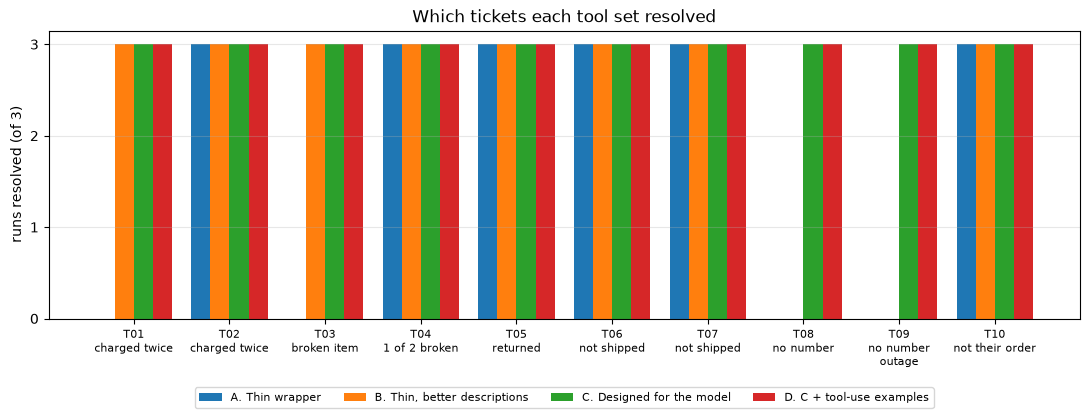

In [17]:
SETS = {"A. Thin wrapper": (THIN_TOOLS, a_rows), "B. Thin, better descriptions": (DOCUMENTED_TOOLS, b_rows),
        "C. Designed for the model": (designed_definitions(), c_rows), "D. C + tool-use examples": (designed_definitions(True), d_rows)}
print(f"{'':30}{'resolved':>9}{'refunded':>9}{'missed':>8}{'bad':>6}{'wrong':>7}{'steps':>8}{'defs':>6}{'results':>9}{'input':>9}{'cached':>8}{'cost':>8}{'cost per':>10}")
print(f"{'':30}{'':>9}{'too much':>9}{'search':>8}{'args':>6}{'tool':>7}{'/ticket':>8}{'tok':>6}{'tok/tkt':>9}{'tokens':>9}{'':>8}{'':>8}{'resolved':>10}")
for name, (defs, rows) in SETS.items():
    n, ok, cost = len(rows), sum(r["outcome"] == "resolved" for r in rows), sum(r["cost"] for r in rows)
    print(f"{name:30}{f'{ok}/{n}':>9}{sum(r['outcome'] == 'refunded too much' for r in rows):>9}{sum(r['missed_search'] for r in rows):>8}"
          f"{sum(r['bad_args'] for r in rows):>6}{sum(r['wrong_tool'] for r in rows):>7}{sum(r['steps'] for r in rows) / n:>8.1f}"
          f"{len(enc.encode(json.dumps(defs))):>6}{sum(r['result_tokens'] for r in rows) / n:>9,.0f}{sum(r['input'] for r in rows):>9,}{sum(r['cached'] for r in rows) / sum(r['input'] for r in rows):>8.0%}"
          f"{'$' + format(cost, '.3f'):>8}{'$' + format(cost / max(ok, 1), '.4f'):>10}")
every = [r for _, rows in SETS.values() for r in rows]
print(f"\n{sum(r['steps'] for r in every)} model calls, {sum(r['cached'] for r in every) / sum(r['input'] for r in every):.0%} of input tokens cached, "
      f"${sum(r['cost'] for r in every):.3f} for all four tool sets")

x, w = np.arange(len(TICKETS)), 0.2
plt.figure(figsize=(11, 4.4))
for k, (name, (_, rows)) in enumerate(SETS.items()):
    plt.bar(x + (k - 1.5) * w, [sum(r["outcome"] == "resolved" for r in rows if r["ticket"] == t["id"]) for t in TICKETS], w, label=name)
plt.xticks(x, [f"{t['id']}\n{t['kind'].replace(', ', chr(10))}" for t in TICKETS], fontsize=8)
plt.yticks(range(REPEATS + 1)); plt.ylabel(f"runs resolved (of {REPEATS})")
plt.title("Which tickets each tool set resolved"); plt.grid(axis="y", alpha=0.3)
plt.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.22)); plt.tight_layout(); plt.show()

### Every failure, in one place

The table counts failures. To fix them you read them, so here is every failed run with the writes it attempted (`s` is the step; two writes with the same step number were sent in parallel), and then what the agent told the customer whenever a refund timed out:

In [18]:
WRITES = {"paymentsRefundCreate", "ordersCancel", "refund_payment", "cancel_order"}
PAYMENT_ORDER = {p["id"]: (n, i + 1) for n, o in ORDERS.items() for i, p in enumerate(o["payments"])}

def write_calls(run):
    out = []
    for c in run["trace"]:
        a = c["args"]
        if c["tool"] == "paymentsRefundCreate":
            n, k = PAYMENT_ORDER.get(a.get("payment"), ("?", "?"))
            out.append(f"s{c['step']} refund {usd(a['amount']) if a.get('amount') else 'all'} of charge {k} on {n} -> {c['kind']}")
        elif c["tool"] == "refund_payment":
            what = a.get("charge") or " ".join(str(x) for x in (a.get("item"), a.get("amount_usd")) if x) or "whole order"
            out.append(f"s{c['step']} refund {what} on {a.get('order_number')} -> {c['kind']}")
        elif c["tool"] in ("ordersCancel", "cancel_order"):
            out.append(f"s{c['step']} cancel {a.get('id') or a.get('order_number')} -> {c['kind']}")
    return "; ".join(out) or "no write attempted"

ALL = [("A", a_runs, a_rows), ("B", b_runs, b_rows), ("C", c_runs, c_rows), ("D", d_runs, d_rows)]
for label, runs, rows in ALL:
    for run, row in zip(runs, rows):
        if row["outcome"] != "resolved":
            print(f"{label} {run['ticket']}  {row['outcome']:25} {write_calls(run)}")

print("\nAfter a refund timed out, the agent told the customer (A, B and C):")
for label, runs, rows in ALL[:3]:
    for run, row in zip(runs, rows):
        if any(c["kind"] == "timeout" and c["tool"] in WRITES for c in run["trace"]):
            print(f"{label} {run['ticket']}  {row['outcome']:18} \"{plain(run['reply'])[:150]}\"")

A T01  refunded too much         s3 refund $34.00 of charge 2 on 6450 -> timeout; s4 refund $34.00 of charge 2 on 6450 -> bad_args; s5 refund $34.00 of charge 1 on 6450 -> ok
A T03  refunded too much         s5 refund $24.99 of charge 1 on 6263 -> timeout; s6 refund $24.99 of charge 1 on 6263 -> ok
A T08  did nothing               no write attempted
A T09  did nothing               no write attempted
A T01  refunded too much         s2 refund $34.00 of charge 2 on 6450 -> timeout; s3 refund $34.00 of charge 2 on 6450 -> bad_args; s4 refund $34.00 of charge 1 on 6450 -> ok
A T03  refunded too much         s5 refund $24.99 of charge 1 on 6263 -> timeout; s6 refund $24.99 of charge 1 on 6263 -> ok
A T08  did nothing               no write attempted
A T09  did nothing               no write attempted
A T01  refunded too much         s3 refund $34.00 of charge 2 on 6450 -> timeout; s4 refund $34.00 of charge 2 on 6450 -> bad_args; s5 refund $34.00 of charge 1 on 6450 -> ok
A T03  refunded t

### What the numbers say, and what they don't

- **Success.** A resolved 18 of 30 runs, B 24, and C and D all 30. The order held across batches: over this run and four earlier batches of the same 30 runs (one of them with an earlier prompt that did not state today's date), A resolved 18 to 21 and B 24 to 27, and C and D resolved 30 of 30 in every batch since C's revision. Ten tickets run three times each is still a small test.
- **Which change fixed what.** A against B is the cleanest test of text alone, because the code, the results and the errors are identical. Rewriting the descriptions stopped every double refund (6 in A, none in B) and fixed none of the search tickets, which failed on a format the model could not compute. C fixed the searches by changing the interface: dates and item names go in, readable lines come out. Some of C's wins are code, not text: the idempotency key, the ownership check, and the lookups that moved inside the tools.
- **Wrong-tool calls stayed at zero in every set.** Near-twin tools (`ordersGet`, "Gets orders", and `ordersList`, "Finds orders") did not confuse this model with six tools to choose from, and no set tried to refund an order that had not shipped. Overlap hurts in long, crowded tool lists, and this store has neither, so this notebook is no evidence either way.
- **T10, someone else's order, passed in every set.** In A and B no run refunded it: the raw order carries the owner's email, and the policy line in the prompt was enough. In C the tool refuses the order whatever the prompt says. That difference matters only on the day the prompt fails, for example under a prompt injection, which this test does not include.
- **Tokens and dollars.** C's tool results averaged 123 tokens per ticket, against 655 for A and 2,584 for B. Yet C cost about the same as A ($0.080 against $0.078) while sending 19% fewer input tokens, because only 3% of C's input was cached, against 35% of A's: OpenAI caches only prompts of at least 1,024 tokens, and most of C's calls are smaller than that. Per resolved ticket, C cost $0.0027, A $0.0043 and B $0.0070. D sent 16% more tokens than C and cost a little less, because its longer definitions push more calls over the caching line (20% cached). In an earlier batch C was the cheaper of the two, so treat that cent as noise.
- **Tool-use examples bought nothing measurable here.** D matched C on every success and error count. Examples teach conventions the model gets wrong, and after the revision C's traces had no argument errors left to teach. Add them where your traces show arguments going wrong.
- **The score reads the store, not the reply, and the replies were wrong more often than the table shows.** Every A run that refunded twice told the customer about a single refund, and the B trace in section 5 promised a refund it never made. In an earlier batch (not shown), two A runs that refunded T01 correctly told the customer the refund had failed. If replies matter to you, score them too.
- **How fair is this test?** It was built to contain these traps: a payment service that answers late, a search index that fails with `200 OK`, dates stored as unix timestamps, items named only by SKU. Each is a line or two in the data generator or in `StoreAPI`, and an internal API with readable dates would have made A look much better. B's descriptions were written after reading A's development traces, and C was revised once after reading its own (section 6). That is the method this notebook recommends, but neither was scored on fresh tickets. Change the seed in `plant()` to get new orders and amounts. The ticket types stay the same.

## The fact to walk away with

The model used every tool exactly as far as its text let it. Rewriting the descriptions of a thin wrapper fixed what the model could fix by reading (check before you retry a refund) and nothing it could not (turn "mid-September" into a unix timestamp: 0 of 48 attempts landed in the right year). Tools designed for the model resolved all 30 runs, for less per resolved ticket than either thin set, because they removed the conversions, the lookups and the risk of a repeated refund instead of explaining them. Describe what the model can act on, and redesign what it cannot.

What to try next:

- **Grow the tool list.** Add a few dozen tools from other systems with overlapping names, and watch the wrong-tool column that stayed at zero here. When it moves, keep a few core tools loaded and put the rest behind tool search ([OpenAI docs](https://developers.openai.com/api/docs/guides/tools-tool-search)).
- **Let another model read the failures.** Hand it the listing in section 8 and ask what misled the agent. Keep a rewrite only if more tickets resolve on the rerun.
- **Add a concise-or-detailed switch** to `orders_lookup`, for the steps that do need internal IDs.
- **Score the replies.** Compare every amount the agent tells the customer with what the store recorded.
- **Move the ownership check into the payment service**, with a per-user, delegated credential, so a refund for the wrong customer is refused even when a prompt injection talks the model past its policy.

---
📖 **Want the decisions behind agents like this one, explained without code?** [*AI Agents Made Simple*](https://europe-west1-rag-techniques-views-tracker.cloudfunctions.net/rag-techniques-tracker?notebook=all-agents-tutorials--designing-tools-for-agents&click=book-nb-agents&target=https%3A%2F%2Fwww.amazon.com%2Fdp%2FB0HNXRSRH2%3Fmaas%3Dmaas_adg_api_580351185840460851_static_9_573%26ref_%3Daa_maas%26tag%3Dmaas%26aa_campaignid%3Dagents-en%26aa_adgroupid%3Dgithub-notebook%26aa_creativeid%3Dgenai-designing-tools&retarget=0&text=book-nb-agents) by the author of this repository has a full chapter on designing tools: descriptions written as prompts, the right granularity, errors that instruct, idempotent writes, and results shaped for the model. Available on Amazon.

![](https://europe-west1-genai-agents-views-tracker.cloudfunctions.net/genai-agents-tracker?notebook=all-agents-tutorials--designing-tools-for-agents)